# Tugas Sub-CLO-12-2-2: Visualisasi Data Geospasial pada Dataset Nyata
## Kemiskinan dan Kebakaran Hutan/Lahan (Karhutla) di 34 Provinsi Indonesia: Perbandingan 2019 vs 2023

| | |
|---|---|
| **Nama** | Naufal Rafif Hidayat |
| **NIM** | 103012300403 |
| **Kelas** | IF-47-GAB01 |
| **Mata Kuliah** | Visualisasi Data |
| **Tanggal Pengerjaan** | 26 November 2026 |

## Deskripsi Dataset

### Sumber data
Dataset ini menggabungkan **tiga sumber terbuka**:

| Komponen | Sumber | Format | Isi |
|---|---|---|---|
| **Geometri wilayah (polygon)** | GADM v4.1, Indonesia level 1: https://gadm.org/download_country.html (file: https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_IDN_1.json.zip) | GeoJSON | 34 polygon provinsi |
| **Data atribut (tabular)** | Badan Pusat Statistik (BPS): https://www.bps.go.id (tautan tiap tabel ada di Daftar Pustaka) | CSV (`data/bps_provinsi.csv`) | % penduduk miskin, IPM, jumlah penduduk, kepadatan penduduk; tahun 2019 & 2023 |
| **Data titik** | NASA FIRMS (Fire Information for Resource Management System), MODIS Collection 6.1 Standard Processing: https://firms.modaps.eosdis.nasa.gov/api/area/ | CSV dari API | Titik panas (hotspot) tahun 2019 & 2023 dengan atribut *confidence*, FRP, *brightness*, tanggal |

Ketentuan tugas terpenuhi: **34 unit wilayah** (≥ 15 polygon), puluhan ribu titik (≥ 100 titik), dan lebih dari 3 variabel numerik (% miskin, IPM, kepadatan penduduk, jumlah hotspot, kepadatan hotspot, FRP, confidence).

### Konteks wilayah
Indonesia adalah negara kepulauan yang membentang ±5.000 km dari 95° BT sampai 141° BT dan dari 6° LU sampai 11° LS, tepat di sekitar garis khatulistiwa. Kebakaran hutan dan lahan (karhutla) terjadi hampir setiap musim kemarau, terutama di Sumatra dan Kalimantan. Dua tahun dipilih sebagai pembanding:
- **2019**: salah satu musim karhutla terparah dalam satu dekade terakhir, dipicu kemarau panjang.
- **2023**: tahun El Niño, yang juga berpotensi memicu kemarau dan kebakaran.

### Tujuan analisis
1. **Di mana** konsentrasi (hotspot) kebakaran terjadi, dan bagaimana polanya berubah dari 2019 ke 2023?
2. Apakah provinsi dengan banyak kebakaran juga merupakan provinsi dengan **kemiskinan tinggi / IPM rendah**?
3. **Kapan** puncak kebakaran terjadi dalam setahun, dan apakah polanya sama pada kedua tahun?
4. Provinsi mana yang perlu menjadi **prioritas intervensi**?

## 0. Setup Lingkungan

Library yang digunakan sesuai materi: **geopandas** (manipulasi data spasial), **geoplot** + **cartopy** (peta & proyeksi), **mapclassify** (skema klasifikasi), **matplotlib** (plotting dasar), dan **imageio** (animasi GIF).
Jika dijalankan di Google Colab, aktifkan baris `pip install` di bawah.

In [1]:
# !pip install geopandas geoplot cartopy matplotlib mapclassify imageio requests

import io, os, time, zipfile, datetime as dt, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import geoplot as gplt
import geoplot.crs as gcrs
import cartopy.crs as ccrs
import mapclassify as mc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import imageio.v2 as imageio
import requests
from shapely.validation import make_valid
from shapely.ops import unary_union
from shapely.geometry import MultiPolygon
from IPython.display import Image, display

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 13, 'axes.titleweight': 'bold'})

DATA_DIR, OUT_DIR = 'data', 'output'
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

TAHUN = [2019, 2023]
PROJ = gcrs.Mercator()          # proyeksi utama (alasan dijelaskan di Bagian 2)
SRC_GEO = 'Batas wilayah: GADM v4.1'
SRC_BPS = 'Atribut: BPS (Badan Pusat Statistik)'
SRC_FIRMS = 'Hotspot: NASA FIRMS MODIS C6.1 (Standard Processing)'

def keterangan(fig, sumber, proyeksi='Proyeksi Mercator (geoplot.crs.Mercator)', jarak=0.3):
    """Menambahkan keterangan proyeksi dan sumber data tepat di bawah peta paling bawah."""
    fig.canvas.draw()
    y0 = min(a.get_position().y0 for a in fig.axes)
    fig.text(0.5, y0 - jarak / fig.get_figheight(), f'{proyeksi}  |  Sumber: {sumber}',
             ha='center', va='top', fontsize=8.5, color='dimgray')

def label_kelas(bins, fmt='{:.1f}', vmin=0):
    """Label legenda yang rapi untuk skema klasifikasi: 'a – b'."""
    lo = [vmin] + list(bins[:-1])
    return [f'{fmt.format(a)} – {fmt.format(b)}'.replace('.', ',') for a, b in zip(lo, bins)]

print('geopandas', gpd.__version__, '| geoplot', gplt.__version__, '| mapclassify', mc.__version__)

geopandas 1.2.0 | geoplot 0.5.1 | mapclassify 2.10.0


## 1. Persiapan Data Geospasial

### 1.1 Memuat data geometri (polygon provinsi)
Batas 34 provinsi diambil dari **GADM v4.1 level 1** dalam format GeoJSON. Jika file belum ada di folder `data/`, notebook akan mengunduhnya otomatis.

In [2]:
GADM_URL = 'https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_IDN_1.json.zip'
GADM_FILE = os.path.join(DATA_DIR, 'gadm41_IDN_1.json')

if not os.path.exists(GADM_FILE):
    r = requests.get(GADM_URL, timeout=300); r.raise_for_status()
    zipfile.ZipFile(io.BytesIO(r.content)).extractall(DATA_DIR)

prov = gpd.read_file(GADM_FILE)[['GID_1', 'NAME_1', 'geometry']]
print('Jumlah unit wilayah :', len(prov))
print('Tipe geometri       :', prov.geom_type.unique())
prov.head()

Jumlah unit wilayah : 34
Tipe geometri       : <StringArray>
['MultiPolygon']
Length: 1, dtype: str


,GID_1,NAME_1,geometry
0,IDN.1_1,Aceh,"MULTIPOLYGON (((96.6813 2.0974, 96.6872 2.0905..."
1,IDN.2_1,Bali,"MULTIPOLYGON (((115.5257 -8.8045, 115.5254 -8...."
2,IDN.3_1,BangkaBelitung,"MULTIPOLYGON (((108.0137 -3.2445, 108.0108 -3...."
3,IDN.4_1,Banten,"MULTIPOLYGON (((106.3868 -6.9907, 106.385 -6.9..."
4,IDN.5_1,Bengkulu,"MULTIPOLYGON (((103.573 -4.923, 103.5713 -4.92..."


### 1.2 Memuat data atribut (BPS) dan menggabungkan (merge)
File `data/bps_provinsi.csv` disusun dari empat tabel resmi BPS (tautan lengkap ada di Daftar Pustaka):

| Kolom | Arti | Tabel BPS |
|---|---|---|
| `miskin_pct_YYYY` | Persentase penduduk miskin (P0), Semester 1 (Maret) | Persentase Penduduk Miskin (P0) Menurut Provinsi dan Daerah |
| `ipm_YYYY` | Indeks Pembangunan Manusia (metode baru) | [Metode Baru] IPM menurut Provinsi |
| `penduduk_ribu_YYYY` | Jumlah penduduk (ribu jiwa) | Penduduk, Laju Pertumbuhan, ..., Kepadatan Penduduk Menurut Provinsi |
| `kepadatan_YYYY` | Kepadatan penduduk (jiwa/km²) | (tabel yang sama) |

Catatan penyelarasan:
- Data kemiskinan dan kependudukan BPS untuk 2019 dan 2023 masih memakai **34 provinsi** (Papua dan Papua Barat sebelum pemekaran), sehingga cocok dengan GADM.
- **IPM 2023** sudah dirilis untuk 38 provinsi. IPM Papua dan Papua Barat (versi 34 provinsi) dihitung ulang sebagai **rata-rata tertimbang jumlah penduduk** dari provinsi-provinsi hasil pemekarannya. Ini adalah pendekatan, bukan angka resmi BPS.

Kunci penggabungan adalah kolom `kode_gadm` (nama provinsi versi GADM, mis. `JakartaRaya`) yang dipetakan ke nama provinsi versi BPS.

In [3]:
bps = pd.read_csv(os.path.join(DATA_DIR, 'bps_provinsi.csv'))

# Cek kecocokan kunci sebelum merge
tidak_cocok = set(prov.NAME_1) ^ set(bps.kode_gadm)
print('Nama provinsi yang tidak cocok:', tidak_cocok or 'tidak ada')

gdf = prov.merge(bps, left_on='NAME_1', right_on='kode_gadm', how='left', validate='one_to_one')
print('Baris setelah merge :', len(gdf), '| nilai atribut kosong:', int(gdf[bps.columns].isna().sum().sum()))
gdf[['NAME_1', 'provinsi', 'miskin_pct_2019', 'miskin_pct_2023', 'ipm_2023', 'kepadatan_2023']].head()

Nama provinsi yang tidak cocok: tidak ada
Baris setelah merge : 34 | nilai atribut kosong: 0


,NAME_1,provinsi,miskin_pct_2019,miskin_pct_2023,ipm_2023,kepadatan_2023
0,Aceh,Aceh,15.32,14.45,73.40,96.0
1,Bali,Bali,3.79,4.25,77.10,788.0
2,BangkaBelitung,Kep. Bangka Belitung,4.62,4.52,72.85,91.0
3,Banten,Banten,5.09,6.17,73.87,1316.0
4,Bengkulu,Bengkulu,15.23,14.04,72.78,104.0


### 1.3 Pemeriksaan Coordinate Reference System (CRS)

In [4]:
print('CRS data geometri :', gdf.crs)
print('Nama CRS          :', gdf.crs.name)
print('Satuan            :', gdf.crs.axis_info[0].unit_name)
print('Batas (lon/lat)   :', np.round(gdf.total_bounds, 2))

CRS data geometri : EPSG:4326
Nama CRS          : WGS 84
Satuan            : degree
Batas (lon/lat)   : [ 95.01 -11.01 141.02   6.08]


**Interpretasi CRS:** Data GADM menggunakan **EPSG:4326 (WGS 84)**, yaitu *geographic CRS* dengan satuan **derajat** (longitude/latitude). CRS ini cocok untuk menyimpan dan menggabungkan data, karena data hotspot NASA FIRMS juga memakai koordinat WGS 84 sehingga keduanya langsung bisa di-*spatial join* tanpa transformasi.

Namun EPSG:4326 **tidak cocok untuk menghitung luas atau jarak**, karena satu derajat tidak setara dengan jarak yang sama di semua lokasi. Oleh karena itu:
- perhitungan **luas provinsi** dilakukan setelah transformasi ke **EPSG:6933** (*WGS 84 / NSIDC EASE-Grid 2.0 Global*, proyeksi *equal-area* dengan satuan meter);
- untuk **visualisasi**, data diproyeksikan ke **Mercator** melalui `geoplot.crs` (alasan pemilihan dijelaskan di Bagian 2).

Rentang koordinat (95,0° s.d. 141,0° BT dan 11,0° LS s.d. 6,1° LU) juga memastikan seluruh polygon berada di wilayah Indonesia dan tidak ada koordinat yang tertukar.

### 1.4 Validasi geometri
Memastikan setiap baris memiliki geometri, tipe geometrinya polygon/multipolygon, dan geometrinya **valid** (tidak ada self-intersection). Geometri tidak valid dapat membuat operasi spasial seperti `sjoin` dan perhitungan luas menjadi salah.

In [5]:
print('Geometri kosong/null :', int(gdf.geometry.isna().sum() + gdf.geometry.is_empty.sum()))
print('Tipe geometri        :', gdf.geom_type.value_counts().to_dict())
invalid = ~gdf.is_valid
print('Geometri tidak valid :', int(invalid.sum()), '->', list(gdf.loc[invalid, 'provinsi']))

# Perbaikan dengan make_valid, lalu cek ulang
gdf.loc[invalid, 'geometry'] = gdf.loc[invalid, 'geometry'].apply(make_valid)
# make_valid dapat menghasilkan GeometryCollection (polygon + garis sisa); ambil bagian polygon-nya saja
def ambil_polygon(g):
    if g.geom_type in ('Polygon', 'MultiPolygon'):
        return g
    return unary_union([p for p in g.geoms if p.geom_type in ('Polygon', 'MultiPolygon')])
gdf['geometry'] = gdf.geometry.apply(ambil_polygon)
print('Setelah perbaikan    : tidak valid =', int((~gdf.is_valid).sum()), '| tipe =', gdf.geom_type.unique())

# Luas wilayah dihitung pada CRS equal-area (EPSG:6933) agar satuannya km² dan tidak terdistorsi
gdf['luas_km2'] = gdf.to_crs(6933).area / 1e6
gdf[['provinsi', 'luas_km2']].sort_values('luas_km2', ascending=False).head()

Geometri kosong/null : 0
Tipe geometri        : {'MultiPolygon': 34}
Geometri tidak valid : 2 -> ['Papua', 'Sulawesi Selatan']


Setelah perbaikan    : tidak valid = 0 | tipe = <StringArray>
['MultiPolygon']
Length: 1, dtype: str


,provinsi,luas_km2
22,Papua,313773.326492
13,Kalimantan Tengah,153711.086199
11,Kalimantan Barat,146869.654239
14,Kalimantan Timur,125829.729561
23,Papua Barat,98500.307117


**Hasil validasi:**
- Tidak ada geometri kosong atau null, dan seluruh 34 baris bertipe **MultiPolygon**. Ini wajar untuk negara kepulauan, karena satu provinsi terdiri dari banyak pulau.
- Ditemukan **2 geometri tidak valid** (Papua dan Sulawesi Selatan), umumnya karena ring polygon yang bersilangan sendiri (*self-intersection*) di garis pantai yang sangat detail. Keduanya diperbaiki dengan `make_valid`, dan hasilnya disaring kembali agar hanya bagian polygon yang tersisa. Setelah perbaikan, seluruh geometri valid.
- Luas yang dihitung pada CRS *equal-area* masuk akal: Papua (±314 ribu km²) dan Kalimantan Tengah (±154 ribu km²) adalah dua provinsi terluas, sesuai urutan luas resmi.

**Penyelarasan IPM 2023 (38 → 34 provinsi).** BPS merilis IPM 2023 untuk 38 provinsi. Agar cocok dengan polygon GADM (34 provinsi), nilai provinsi hasil pemekaran digabung kembali dengan rata-rata tertimbang jumlah penduduk. Bobotnya memakai jumlah penduduk 2026 dari tabel BPS yang sama, karena tabel 2023 masih disajikan dalam 34 provinsi.

| Provinsi (34) | Gabungan dari (IPM 2023) | IPM gabungan |
|---|---|---|
| Papua Barat | Papua Barat (66,16), Papua Barat Daya (68,05) | **67,14** |
| Papua | Papua (72,41), Papua Selatan (67,27), Papua Tengah (58,93), Papua Pegunungan (52,45) | **60,98** |

Angka gabungan ini adalah **pendekatan**, bukan angka resmi BPS.

### 1.5 Memuat data titik panas (hotspot) NASA FIRMS
Data titik berasal dari **NASA FIRMS, sensor MODIS (Terra & Aqua) Collection 6.1, Standard Processing (`MODIS_SP`)** untuk kotak wilayah Indonesia (94°–141,5° BT, 11,5° LS–6,5° LU), 1 Januari–31 Desember 2019 dan 2023.

- API FIRMS membatasi satu permintaan maksimal **5 hari**, sehingga pengunduhan dilakukan berulang lalu digabung.
- Hasil unduhan disimpan ke `data/firms_modis_YYYY.csv`. Notebook **membaca file lokal** tersebut, dan kode unduh hanya berjalan jika file belum ada. Dengan begitu *Run All* tidak membutuhkan MAP_KEY.
- MAP_KEY dibaca dari file `firms_key.txt` (tidak ditulis di notebook).

In [6]:
FIRMS_BBOX = '94,-11.5,141.5,6.5'

def unduh_firms(tahun, key_file='firms_key.txt'):
    """Mengunduh hotspot MODIS_SP satu tahun penuh (per 5 hari) dari API NASA FIRMS."""
    key = open(key_file).read().strip()
    frames, d, akhir = [], dt.date(tahun, 1, 1), dt.date(tahun, 12, 31)
    while d <= akhir:
        n = min(5, (akhir - d).days + 1)
        url = f'https://firms.modaps.eosdis.nasa.gov/api/area/csv/{key}/MODIS_SP/{FIRMS_BBOX}/{n}/{d}'
        r = requests.get(url, timeout=120); r.raise_for_status()
        frames.append(pd.read_csv(io.StringIO(r.text)))
        d += dt.timedelta(days=n); time.sleep(1)
    return pd.concat(frames, ignore_index=True).drop_duplicates()

raw = []
for th in TAHUN:
    f = os.path.join(DATA_DIR, f'firms_modis_{th}.csv')
    if not os.path.exists(f):
        unduh_firms(th).to_csv(f, index=False)
    raw.append(pd.read_csv(f, parse_dates=['acq_date']).assign(tahun=th))
raw = pd.concat(raw, ignore_index=True)
print('Total deteksi mentah:', raw.groupby('tahun').size().to_dict())
raw[['latitude', 'longitude', 'acq_date', 'confidence', 'frp', 'brightness', 'type']].head()

Total deteksi mentah: {2019: 101691, 2023: 60552}


,latitude,longitude,acq_date,confidence,frp,brightness,type
0,-4.0605,135.7863,2019-01-01,83,24.1,326.1,0
1,-4.0591,135.7771,2019-01-01,42,5.0,305.3,0
2,-4.0530,136.6032,2019-01-01,72,9.1,313.3,0
3,5.8294,114.3451,2019-01-01,46,7.3,311.1,3
4,6.0778,125.0618,2019-01-02,51,11.1,313.9,0


**Pembersihan data titik:**
1. `confidence ≥ 30`: deteksi dengan kepercayaan rendah (< 30%) dibuang untuk mengurangi *false alarm*.
2. `type == 0`: hanya *presumed vegetation fire*. Tipe 1 (gunung api aktif), 2 (sumber panas statis lain, mis. industri), dan 3 (deteksi lepas pantai) dibuang karena bukan karhutla.
3. **Spatial join** titik ke polygon provinsi (`predicate='within'`) untuk memberi label provinsi pada setiap titik. Titik yang jatuh di laut atau di luar Indonesia (mis. Malaysia, Timor Leste) otomatis terbuang.

In [7]:
pts = raw[(raw.confidence >= 30) & (raw['type'] == 0)].copy()
pts = gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy(pts.longitude, pts.latitude), crs='EPSG:4326')
print('CRS titik sama dengan CRS polygon:', pts.crs == gdf.crs)

pts = gpd.sjoin(pts, gdf[['provinsi', 'geometry']], how='inner', predicate='within').drop(columns='index_right')
pts['bulan'] = pts.acq_date.dt.month
print('Tipe geometri titik :', pts.geom_type.unique(), '| valid semua:', bool(pts.is_valid.all()))
print('Hotspot bersih per tahun:', pts.groupby('tahun').size().to_dict())

CRS titik sama dengan CRS polygon: True


Tipe geometri titik : <StringArray>
['Point']
Length: 1, dtype: str | valid semua: True
Hotspot bersih per tahun: {2019: 80531, 2023: 45092}


### 1.6 Agregasi titik ke tingkat provinsi
Untuk choropleth, titik dihitung per provinsi. Karena luas provinsi sangat berbeda (Papua ±300 ribu km² vs DKI ±660 km²), jumlah hotspot juga dinormalisasi menjadi **kepadatan hotspot per 1.000 km²**. Choropleth sebaiknya memakai nilai yang dinormalisasi, bukan nilai absolut.

In [8]:
agg = (pts.groupby(['provinsi', 'tahun'])
          .agg(hotspot=('frp', 'size'), frp_rata=('frp', 'mean'))
          .unstack('tahun'))
agg.columns = [f'{a}_{b}' for a, b in agg.columns]
gdf = gdf.merge(agg, left_on='provinsi', right_index=True, how='left')
for th in TAHUN:
    gdf[f'hotspot_{th}'] = gdf[f'hotspot_{th}'].fillna(0).astype(int)
    gdf[f'dens_hotspot_{th}'] = gdf[f'hotspot_{th}'] / gdf.luas_km2 * 1000
gdf['d_miskin'] = gdf.miskin_pct_2023 - gdf.miskin_pct_2019

# Versi geometri yang disederhanakan (toleransi ~1 km) khusus untuk plotting agar cepat
gplot = gdf.copy()
# orient_polygons(): menyeragamkan arah ring polygon (exterior berlawanan arah jarum jam).
# GADM menyimpan sebagian ring searah jarum jam; tanpa ini cartopy dapat salah mengisi "kebalikan" polygon.
gplot['geometry'] = gplot.simplify(0.01, preserve_topology=True).orient_polygons()

VARS = ['miskin_pct_2019', 'miskin_pct_2023', 'ipm_2019', 'ipm_2023', 'kepadatan_2023',
        'hotspot_2019', 'hotspot_2023', 'dens_hotspot_2019', 'dens_hotspot_2023']
gdf[VARS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
miskin_pct_2019,34.0,10.45,5.68,3.47,6.47,8.76,13.29,27.53
miskin_pct_2023,34.0,10.09,5.18,4.25,6.24,8.43,12.25,26.03
ipm_2019,34.0,71.04,3.91,60.84,69.46,71.24,72.30,80.76
ipm_2023,34.0,72.60,3.95,60.98,70.94,72.78,73.75,82.46
kepadatan_2023,34.0,752.65,2749.12,10.00,56.00,102.50,272.75,16146.00
hotspot_2019,34.0,2368.56,3927.17,0.00,237.50,681.50,2858.50,17821.00
hotspot_2023,34.0,1326.24,2033.35,0.00,118.50,468.00,1163.75,7163.00
dens_hotspot_2019,34.0,35.97,37.82,0.00,7.60,18.04,60.47,128.82
dens_hotspot_2023,34.0,19.98,21.49,0.00,5.63,11.66,22.62,77.24


In [9]:
(gdf[['provinsi', 'miskin_pct_2023', 'ipm_2023', 'hotspot_2019', 'hotspot_2023', 'dens_hotspot_2019', 'dens_hotspot_2023']]
   .sort_values('hotspot_2019', ascending=False).head(10).round(2).reset_index(drop=True))

,provinsi,miskin_pct_2023,ipm_2023,hotspot_2019,hotspot_2023,dens_hotspot_2019,dens_hotspot_2023
0,Kalimantan Tengah,5.11,72.20,17821,7154,115.94,46.54
1,Kalimantan Barat,6.71,69.41,10519,7163,71.62,48.77
2,Sumatera Selatan,11.78,71.62,10264,5860,118.00,67.37
3,Riau,6.68,74.04,7952,1234,88.48,13.73
4,Jambi,7.58,72.77,6307,587,128.82,11.99
5,Kalimantan Timur,6.11,78.20,3903,2435,31.02,19.35
6,Kalimantan Selatan,4.29,72.50,3477,2660,93.05,71.19
7,Nusa Tenggara Timur,19.96,66.68,3471,3588,74.72,77.24
8,Papua,26.03,60.98,3198,4984,10.19,15.88
9,Lampung,11.11,71.15,1840,1196,54.95,35.71


**Interpretasi hasil persiapan data titik:**
- Dari 101.691 deteksi mentah tahun 2019 dan 60.552 deteksi tahun 2023, tersisa **80.531** dan **45.092** hotspot karhutla setelah disaring (confidence ≥ 30, tipe vegetasi, dan berada di daratan Indonesia). Jumlah hotspot 2023 **turun ±44%** dibanding 2019.
- Distribusi jumlah hotspot per provinsi **sangat menceng ke kanan** (*right-skewed*): median 2019 hanya 682 titik, tetapi maksimumnya 17.821 titik (Kalimantan Tengah). Sebagian kecil provinsi menyumbang sebagian besar kebakaran, dan sifat ini akan memengaruhi pilihan skema klasifikasi di Bagian 3.
- Pada 2019, lima provinsi teratas berdasarkan jumlah hotspot seluruhnya berada di **Kalimantan dan Sumatra bagian tengah-selatan**: Kalimantan Tengah, Kalimantan Barat, Sumatera Selatan, Riau, dan Jambi.
- Setelah dinormalisasi per luas, urutannya berubah. **Jambi** (128,8 hotspot/1.000 km²) dan **Sumatera Selatan** (118,0) justru lebih padat daripada Kalimantan Tengah (115,9). Contoh ini menunjukkan pentingnya normalisasi sebelum membuat choropleth.

## 2. Peta Dasar (Polyplot) dan Pemilihan Proyeksi

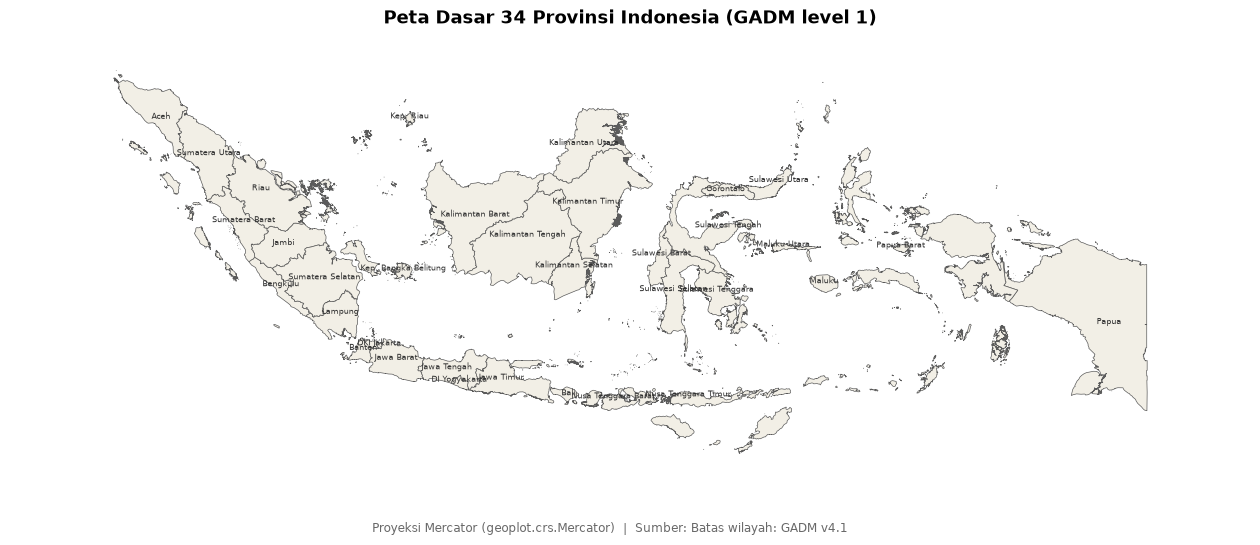

In [10]:
fig, ax = plt.subplots(figsize=(16, 7), subplot_kw={'projection': PROJ})
gplt.polyplot(gplot, ax=ax, facecolor='#f2efe6', edgecolor='#5b5b5b', linewidth=0.5)
for _, r in gplot.iterrows():
    p = r.geometry.representative_point()
    ax.text(p.x, p.y, r.provinsi, transform=ccrs.PlateCarree(), fontsize=6, ha='center', color='#333')
ax.set_title('Peta Dasar 34 Provinsi Indonesia (GADM level 1)')
keterangan(fig, SRC_GEO)
plt.savefig(f'{OUT_DIR}/01_polyplot.png', bbox_inches='tight'); plt.show()

**Alasan pemilihan proyeksi Mercator:**

1. **Letak geografis.** Indonesia berada di sekitar khatulistiwa (±6° LU s.d. 11° LS). Distorsi skala Mercator naik sebanding dengan $\sec(\varphi)$. Pada lintang 11° faktornya hanya $\sec(11°) ≈ 1{,}02$, artinya distorsi luas dan jarak **kurang dari ±4%** di seluruh wilayah kajian. Distorsi ekstrem Mercator (mis. Greenland terlihat sebesar Afrika) hanya terjadi di lintang tinggi, sehingga tidak relevan untuk Indonesia.
2. **Konformal.** Mercator mempertahankan bentuk lokal (sudut), sehingga bentuk pulau dan garis pantai tampak alami dan mudah dikenali pembaca.
3. **Bentang timur–barat yang panjang.** Indonesia jauh lebih lebar (±46° bujur) daripada tingginya (±17° lintang). Mercator menampilkannya dalam bingkai persegi panjang yang efisien.
4. **Perbandingan dengan proyeksi lain:**
   - **Albers Equal-Area** dan **Lambert Conformal Conic** adalah proyeksi kerucut yang dirancang untuk wilayah **lintang tengah** dengan dua *standard parallel* (mis. Amerika Serikat). Untuk wilayah yang memotong ekuator, kedua *standard parallel* harus diletakkan di kedua sisi ekuator, dan kelebihannya dibanding Mercator menjadi tidak berarti.
   - **Stereographic** cocok untuk wilayah kutub atau wilayah kecil yang berbentuk bulat, bukan untuk kepulauan yang memanjang.

Karena perhitungan kuantitatif (luas, kepadatan) tetap dilakukan pada CRS *equal-area* (EPSG:6933), pemakaian Mercator untuk tampilan tidak mengganggu akurasi analisis.

**Hasil peta dasar:** Peta memperlihatkan 34 provinsi dengan konsentrasi provinsi kecil di Jawa–Bali–Nusa Tenggara, serta provinsi yang sangat luas di Kalimantan dan Papua. Perbedaan luas yang ekstrem ini menjadi alasan choropleth jumlah hotspot harus dinormalisasi per luas wilayah.

## 3. Choropleth Mapping

### 3.1 Persentase penduduk miskin 2023 (sequential)
Data kemiskinan bersifat terurut (semakin tinggi semakin buruk) tanpa titik tengah yang bermakna, sehingga dipakai colormap **sequential** `OrRd`.

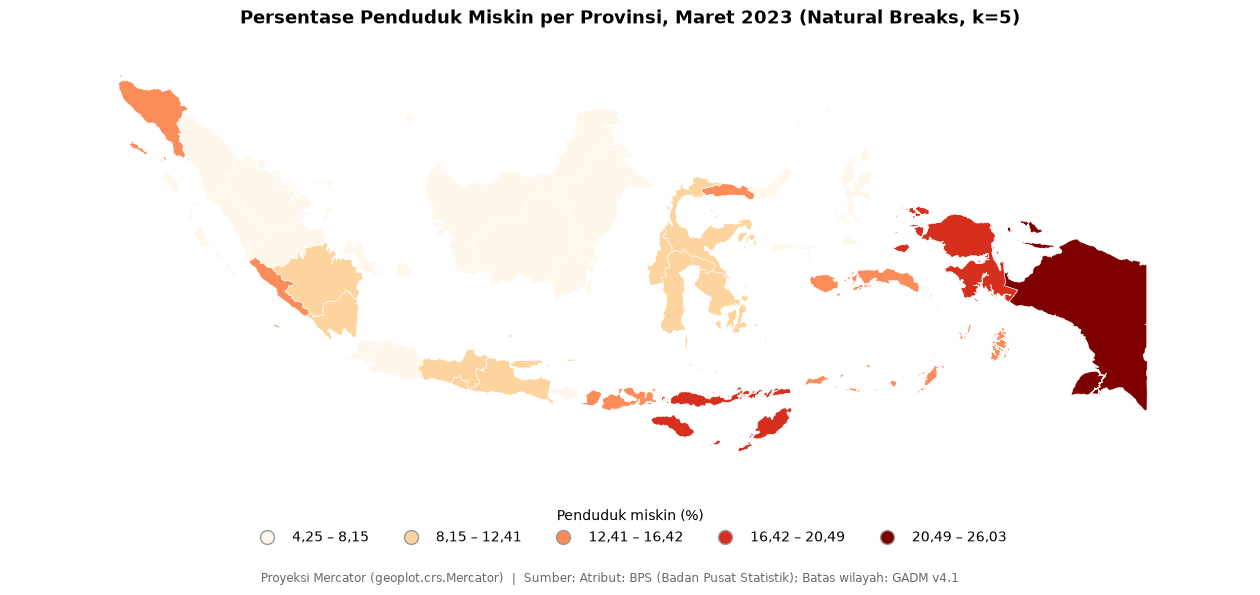

In [11]:
fig, ax = plt.subplots(figsize=(16, 7), subplot_kw={'projection': PROJ})
gplt.choropleth(gplot, hue='miskin_pct_2023', scheme=mc.FisherJenks(gplot.miskin_pct_2023, k=5),
                cmap='OrRd', edgecolor='white', linewidth=0.4, ax=ax, legend=True,
                legend_labels=label_kelas(mc.FisherJenks(gplot.miskin_pct_2023, k=5).bins, '{:.2f}', vmin=gplot.miskin_pct_2023.min()),
                legend_kwargs={'loc': 'upper center', 'bbox_to_anchor': (0.5, -0.01), 'ncol': 5, 'frameon': False, 'title': 'Penduduk miskin (%)', 'markeredgecolor': '#999'})
ax.set_title('Persentase Penduduk Miskin per Provinsi, Maret 2023 (Natural Breaks, k=5)')
keterangan(fig, f'{SRC_BPS}; {SRC_GEO}', jarak=0.8)
plt.savefig(f'{OUT_DIR}/02_choro_miskin_2023.png', bbox_inches='tight'); plt.show()

**Interpretasi:**
- Kemiskinan memperlihatkan **pola barat–timur yang jelas**. Kelas tertinggi (20,49–26,03%) ditempati **Papua (26,03%)** dan **Papua Barat (20,49%)**. Kelas berikutnya diisi **NTT (19,96%)** dan **Maluku (16,42%)**.
- Seluruh Kalimantan, sebagian besar Sumatra, serta Bali, DKI Jakarta, dan Banten berada di kelas terendah (≤ 8,15%). Persentase terendah ada di **Bali (4,25%)**, **Kalimantan Selatan (4,29%)**, dan **DKI Jakarta (4,44%)**.
- Ada pengecualian di barat: **Aceh (14,45%)**, **Bengkulu (14,04%)**, dan **Sumatera Selatan (11,78%)** lebih tinggi daripada provinsi sekitarnya.
- Natural Breaks dipakai di sini karena distribusi kemiskinan memiliki ekor panjang (Papua jauh di atas provinsi lain), sehingga batas kelas lebih baik mengikuti celah alami data.

### 3.2 Kepadatan hotspot 2019 vs 2023 (sequential, skema yang sama)
Agar kedua tahun bisa dibandingkan secara adil, **batas kelas dibuat sama** untuk 2019 dan 2023 (`mapclassify.UserDefined`). Batas kelas dihitung dengan Natural Breaks dari gabungan data dua tahun.

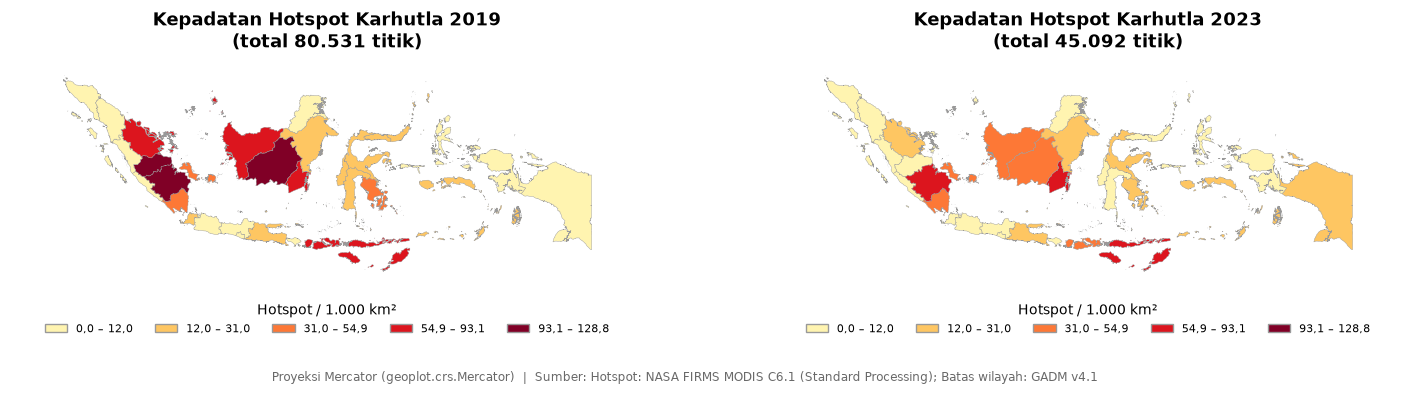

In [12]:
gab = pd.concat([gplot.dens_hotspot_2019, gplot.dens_hotspot_2023])
batas = list(mc.FisherJenks(gab, k=5).bins)

# Warna kelas dikunci (kelas ke-i selalu warna ke-i) agar 2019 dan 2023 benar-benar sebanding,
# walaupun pada salah satu tahun ada kelas yang kosong.
warna = plt.get_cmap('YlOrRd')(np.linspace(0.08, 1, 5))
cmap5 = mcolors.ListedColormap(warna)
norm5 = mcolors.BoundaryNorm(np.arange(-0.5, 5.5), 5)

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), subplot_kw={'projection': PROJ})
for ax, th in zip(axes, TAHUN):
    gplot[f'kelas_{th}'] = mc.UserDefined(gplot[f'dens_hotspot_{th}'], bins=batas).yb
    gplt.choropleth(gplot, hue=f'kelas_{th}', cmap=cmap5, norm=norm5, edgecolor='#999', linewidth=0.3, ax=ax)
    ax.legend([plt.Rectangle((0, 0), 1, 1, fc=c, ec='#999') for c in warna], label_kelas(batas),
              loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=5, frameon=False,
              title='Hotspot / 1.000 km²', fontsize=8)
    ax.set_title(f'Kepadatan Hotspot Karhutla {th}\n(total {int(gplot[f"hotspot_{th}"].sum()):,} titik)'.replace(',', '.'))
keterangan(fig, f'{SRC_FIRMS}; {SRC_GEO}', jarak=0.8)
plt.savefig(f'{OUT_DIR}/03_choro_hotspot_2019_2023.png', bbox_inches='tight'); plt.show()

**Interpretasi:**
- Pada **2019**, kelas tertinggi (93–129 hotspot/1.000 km²) ditempati **Jambi, Sumatera Selatan, dan Kalimantan Tengah**, sedangkan **Riau** dan **Kalimantan Barat/Selatan** berada di kelas kedua tertinggi. Pola ini membentuk **dua klaster besar**: Sumatra bagian tengah-selatan dan Kalimantan bagian barat-tengah.
- Pada **2023**, tidak ada provinsi yang masuk kelas tertinggi. Klaster Sumatra **menyusut tajam**: Riau turun dari 88,5 menjadi 13,7 dan Jambi dari 128,8 menjadi 12,0 hotspot/1.000 km². **Sumatera Selatan** tetap menonjol (67,4).
- Sebaliknya, ada provinsi yang **naik**: **NTT** menjadi provinsi terpadat pada 2023 (77,2), **Papua** naik dari 10,2 menjadi 15,9, dan **Kalimantan Selatan** tetap tinggi (71,2). Pusat gravitasi kebakaran **bergeser ke timur dan selatan**.
- Karena kelas dan warna dikunci sama pada kedua peta, perubahan warna antar tahun mencerminkan perubahan nilai yang sesungguhnya, bukan perbedaan batas kelas.

### 3.3 Perbandingan skema klasifikasi pada variabel kepadatan hotspot 2019
Tiga skema klasifikasi dari **mapclassify** diterapkan pada variabel yang sama dengan jumlah kelas yang sama (k = 5):

- **Quantiles**: setiap kelas berisi jumlah provinsi yang (hampir) sama.
- **Equal Interval**: rentang nilai dibagi menjadi 5 interval sama lebar.
- **Natural Breaks (Fisher-Jenks)**: batas kelas diletakkan pada "celah" alami data dengan meminimalkan variansi di dalam kelas.

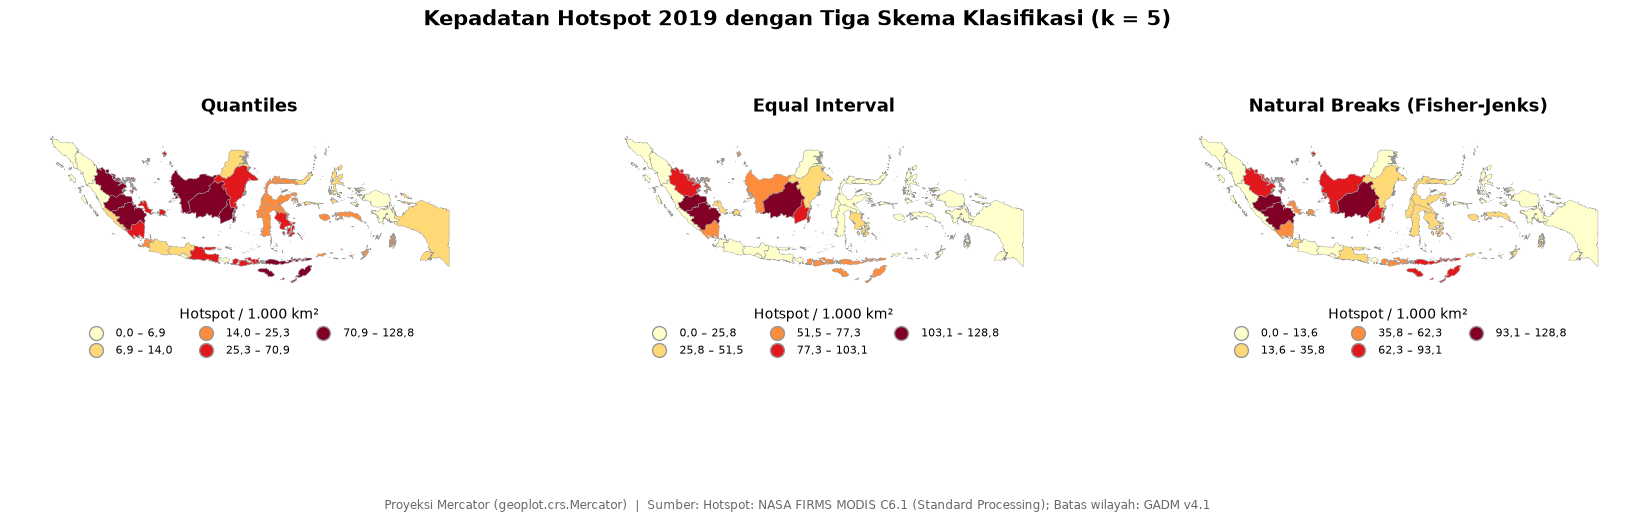

,Quantiles,Equal Interval,Natural Breaks (Fisher-Jenks)
Kelas 1,≤ 6.9 (7 prov),≤ 25.8 (21 prov),≤ 13.6 (14 prov)
Kelas 2,≤ 14.0 (7 prov),≤ 51.5 (3 prov),≤ 35.8 (9 prov)
Kelas 3,≤ 25.3 (6 prov),≤ 77.3 (5 prov),≤ 62.3 (3 prov)
Kelas 4,≤ 70.9 (7 prov),≤ 103.1 (2 prov),≤ 93.1 (5 prov)
Kelas 5,≤ 128.8 (7 prov),≤ 128.8 (3 prov),≤ 128.8 (3 prov)


In [13]:
v = gplot.dens_hotspot_2019
skema = {'Quantiles': mc.Quantiles(v, k=5),
         'Equal Interval': mc.EqualInterval(v, k=5),
         'Natural Breaks (Fisher-Jenks)': mc.FisherJenks(v, k=5)}

fig, axes = plt.subplots(1, 3, figsize=(21, 4.2), subplot_kw={'projection': PROJ})
for ax, (nama, s) in zip(axes, skema.items()):
    gplt.choropleth(gplot, hue='dens_hotspot_2019', scheme=s, cmap='YlOrRd', edgecolor='#999', linewidth=0.3,
                    ax=ax, legend=True, legend_labels=label_kelas(s.bins),
                    legend_kwargs={'loc': 'upper center', 'bbox_to_anchor': (0.5, 0.0), 'ncol': 3, 'fontsize': 8,
                                   'title': 'Hotspot / 1.000 km²', 'frameon': False})
    ax.set_title(nama)
fig.suptitle('Kepadatan Hotspot 2019 dengan Tiga Skema Klasifikasi (k = 5)', fontsize=15, fontweight='bold', y=0.97)
fig.text(0.5, -0.22, f'Proyeksi Mercator (geoplot.crs.Mercator)  |  Sumber: {SRC_FIRMS}; {SRC_GEO}', ha='center', fontsize=8.5, color='dimgray')
plt.savefig(f'{OUT_DIR}/04_perbandingan_skema.png', bbox_inches='tight'); plt.show()

# Tabel batas kelas dan jumlah provinsi per kelas
pd.DataFrame({nama: [f'≤ {b:,.1f}  ({c} prov)' for b, c in zip(s.bins, s.counts)] for nama, s in skema.items()},
             index=[f'Kelas {i}' for i in range(1, 6)])

In [14]:
# Goodness of Absolute Deviation Fit (GADF): makin mendekati 1, makin homogen nilai di dalam tiap kelas
pd.Series({nama: round(s.get_gadf(), 3) for nama, s in skema.items()}, name='GADF (makin besar makin baik)').to_frame()

,GADF (makin besar makin baik)
Quantiles,0.719
Equal Interval,0.795
Natural Breaks (Fisher-Jenks),0.829


**Perbedaan pola antar skema klasifikasi:**

| Aspek | Quantiles | Equal Interval | Natural Breaks (Fisher-Jenks) |
|---|---|---|---|
| Jumlah provinsi per kelas | Rata (7-7-6-7-7) | Sangat timpang (21-3-5-2-3) | Mengikuti data (14-9-3-5-3) |
| Kesan visual | Peta tampak "panas": 14 provinsi berwarna merah tua/merah | Peta tampak "dingin": 21 provinsi berwarna paling terang | Seimbang, hanya klaster yang benar-benar tinggi yang menonjol |
| GADF (homogenitas kelas) | 0,719 (terendah) | 0,795 | **0,829 (tertinggi)** |

- **Quantiles** memaksa setiap kelas berisi ±7 provinsi. Akibatnya, provinsi dengan nilai yang berbeda jauh dikelompokkan bersama. Kelas tertinggi (70,9–128,8) menyatukan Kalimantan Barat (71,6) dengan Jambi (128,8), dan kelas merah (25,3–70,9) menyatukan Jawa Timur (25,3) dengan Kepulauan Riau (70,4) yang hampir 3 kali lipatnya. Provinsi bernilai sedang seperti Jawa Timur dan Sulawesi Tenggara pun tampak seolah-olah "parah". Quantiles **melebih-lebihkan** jumlah wilayah bermasalah. Skema ini berguna untuk melihat **peringkat relatif**, tetapi menyesatkan untuk menilai besaran.
- **Equal Interval** membagi rentang 0–128,8 menjadi 5 interval sama lebar (±25,8). Karena datanya menceng, **21 dari 34 provinsi menumpuk di kelas pertama**, sehingga variasi di antara provinsi bernilai rendah-sedang (mis. Sulawesi vs Papua) **hilang**. Kelebihannya, batas kelasnya intuitif dan mudah dijelaskan.
- **Natural Breaks** meletakkan batas pada celah alami data dan menghasilkan GADF tertinggi (0,829). Artinya, nilai di dalam tiap kelas paling homogen. Peta ini paling jujur memperlihatkan bahwa kebakaran 2019 terkonsentrasi di segelintir provinsi Sumatra dan Kalimantan, sementara sebagian besar provinsi lain relatif rendah.

**Kesimpulan:** untuk data kepadatan hotspot yang sangat menceng ini, **Natural Breaks** adalah skema yang paling tepat dan karena itu dipakai pada peta perbandingan 2019 vs 2023. Perbandingan ini juga menunjukkan bahwa **pilihan skema klasifikasi dapat mengubah pesan sebuah peta**, walaupun datanya sama persis.

### 3.4 Perubahan persentase penduduk miskin 2019 → 2023 (diverging)
Perubahan (dalam poin persen) memiliki **titik tengah yang bermakna, yaitu 0** (tidak berubah). Karena itu dipakai colormap **diverging** `RdBu_r` dengan `TwoSlopeNorm` yang memusatkan warna putih pada 0: biru berarti kemiskinan turun, merah berarti naik.

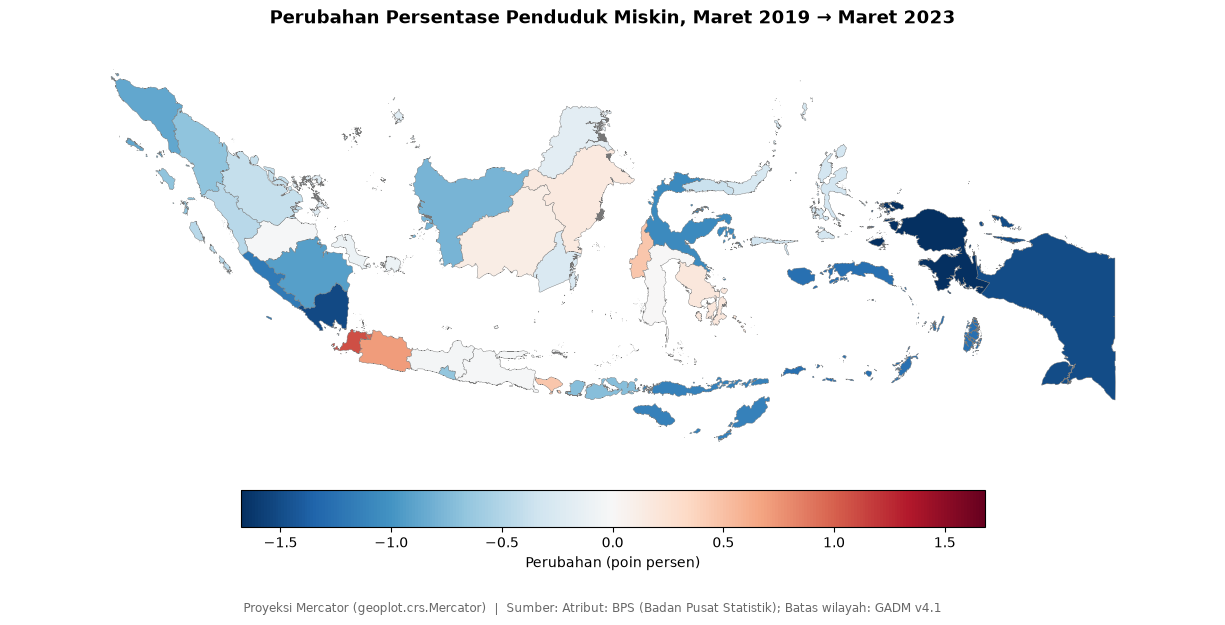

,provinsi,miskin_pct_2019,miskin_pct_2023,d_miskin
23,Papua Barat,22.17,20.49,-1.68
17,Lampung,12.62,11.11,-1.51
22,Papua,27.53,26.03,-1.50
8,Jawa Barat,6.91,7.62,0.71
6,DKI Jakarta,3.47,4.44,0.97
3,Banten,5.09,6.17,1.08


In [15]:
lim = np.abs(gplot.d_miskin).max()
norm = mcolors.TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)

fig, ax = plt.subplots(figsize=(16, 7), subplot_kw={'projection': PROJ})
gplt.choropleth(gplot, hue='d_miskin', cmap='RdBu_r', norm=norm, edgecolor='#777', linewidth=0.3, ax=ax,
                legend=True, legend_kwargs={'shrink': 0.6, 'label': 'Perubahan (poin persen)', 'orientation': 'horizontal', 'pad': 0.02})
ax.set_title('Perubahan Persentase Penduduk Miskin, Maret 2019 → Maret 2023')
keterangan(fig, f'{SRC_BPS}; {SRC_GEO}', jarak=0.75)
plt.savefig(f'{OUT_DIR}/05_choro_perubahan_miskin.png', bbox_inches='tight'); plt.show()

gdf[['provinsi', 'miskin_pct_2019', 'miskin_pct_2023', 'd_miskin']].sort_values('d_miskin').iloc[[0, 1, 2, -3, -2, -1]].round(2)

**Interpretasi:**
- Sebagian besar provinsi berwarna **biru** (kemiskinan turun). Penurunan terbesar terjadi di **Papua Barat (−1,68 poin)**, **Lampung (−1,51)**, dan **Papua (−1,50)**. Meskipun turun paling banyak, Papua dan Papua Barat tetap menjadi provinsi termiskin.
- Provinsi yang berwarna **merah** (kemiskinan naik) justru terkonsentrasi di **Jawa bagian barat**: **Banten (+1,08)**, **DKI Jakarta (+0,97)**, dan **Jawa Barat (+0,71)**, ditambah sebagian Kalimantan dan Sulawesi (mis. Kalimantan Tengah, Sulawesi Barat). Pola ini konsisten dengan dampak pandemi 2020–2021 yang lebih berat bagi perekonomian perkotaan dan belum sepenuhnya pulih pada 2023.
- Colormap diverging dengan titik tengah 0 membuat arah perubahan (naik/turun) langsung terbaca dari warnanya. Jika dipakai colormap sequential, provinsi yang naik sedikit dan yang turun sedikit akan sulit dibedakan.

## 4. Representasi Multi-Dimensi & Overlay Layer

Satu peta menumpuk **dua layer**:
1. **Layer dasar**: choropleth persentase penduduk miskin (dimensi 1, warna polygon).
2. **Layer titik**: `gplt.pointplot` hotspot dengan **hue = confidence** (dimensi 2, warna titik) dan **scale = FRP** (*Fire Radiative Power*, MW; dimensi 3, ukuran titik). FRP menggambarkan intensitas energi api.

Untuk menghindari *overplotting*, layer titik hanya menampilkan hotspot dengan confidence ≥ 80 (kategori *high*).

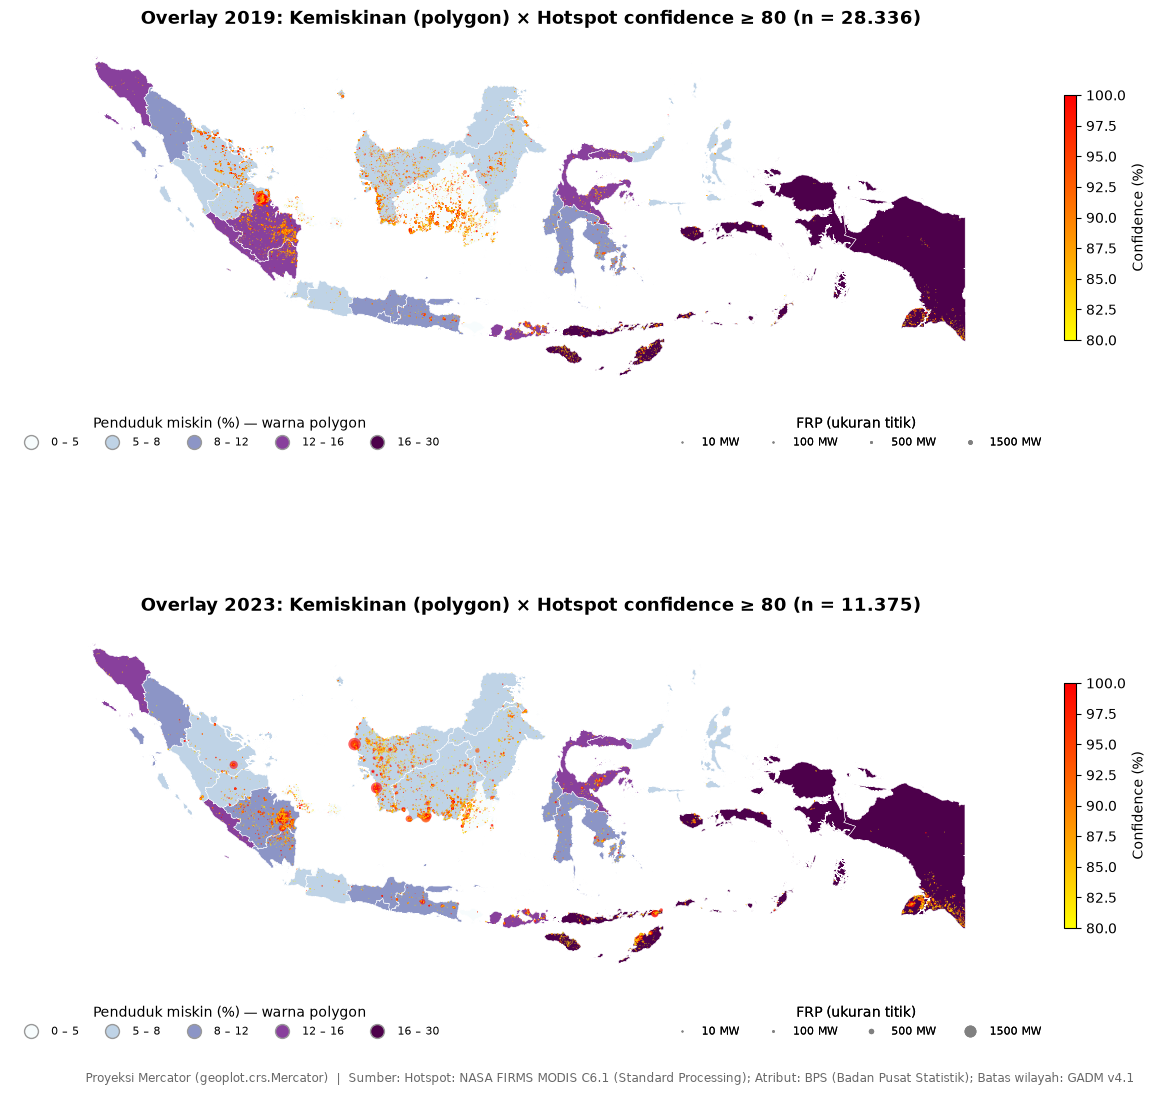

In [16]:
def legenda_ukuran(ax, nilai=(10, 100, 500, 1500), limits=(0.5, 9), vmax=None):
    """Legenda manual untuk skala ukuran titik (geoplot hanya menampilkan satu legenda per peta)."""
    vmin = 0
    size = lambda v: limits[0] + (limits[1] - limits[0]) * (v - vmin) / (vmax - vmin)
    h = [Line2D([], [], marker='o', ls='', color='gray', markersize=size(v)) for v in nilai]
    ax.add_artist(ax.legend(h, [f'{v} MW' for v in nilai], title='FRP (ukuran titik)', loc='upper right',
                            bbox_to_anchor=(1.0, -0.01), ncol=4, fontsize=8, frameon=False))

fig, axes = plt.subplots(2, 1, figsize=(16, 14), subplot_kw={'projection': PROJ})
for ax, th in zip(axes, TAHUN):
    p = pts[(pts.tahun == th) & (pts.confidence >= 80)].sort_values('frp')
    vmax = p.frp.max()
    gplt.choropleth(gplot, hue=f'miskin_pct_{th}', scheme=mc.UserDefined(gplot[f'miskin_pct_{th}'], bins=[5, 8, 12, 16, 30]),
                    cmap='BuPu', edgecolor='white', linewidth=0.4, ax=ax, legend=True, legend_labels=label_kelas([5, 8, 12, 16, 30], '{:.0f}'),
                    legend_kwargs={'loc': 'upper left', 'bbox_to_anchor': (0.0, -0.01), 'ncol': 5, 'frameon': False,
                                   'title': 'Penduduk miskin (%) — warna polygon', 'fontsize': 8, 'markeredgecolor': '#999'})
    ax.add_artist(ax.get_legend())   # simpan legenda choropleth agar tidak tertimpa legenda layer titik
    gplt.pointplot(p, hue='confidence', cmap='autumn_r', scale='frp', limits=(0.5, 9), ax=ax, alpha=0.6, zorder=5,
                   edgecolor='none', legend=True, legend_var='hue',
                   legend_kwargs={'shrink': 0.5, 'label': 'Confidence (%)', 'orientation': 'vertical', 'pad': 0.01})
    legenda_ukuran(ax, vmax=vmax)
    ax.set_title(f'Overlay {th}: Kemiskinan (polygon) × Hotspot confidence ≥ 80 (n = {len(p):,})'.replace(',', '.'))
keterangan(fig, f'{SRC_FIRMS}; {SRC_BPS}; {SRC_GEO}', jarak=0.8)
plt.savefig(f'{OUT_DIR}/06_overlay_kemiskinan_hotspot.png', bbox_inches='tight'); plt.show()

**Interpretasi peta overlay (3 dimensi dalam satu peta):**
- **Lokasi titik dan warna polygon tidak selaras.** Titik api terpadat pada 2019 berada di **Kalimantan Tengah, Kalimantan Barat, Riau, dan Jambi**, yang semuanya berwarna terang (kemiskinan 5–8%, di bawah rata-rata nasional 9,4%). Provinsi termiskin (Papua dan Papua Barat, warna ungu tua) justru relatif sedikit titiknya pada 2019.
- **Sumatera Selatan** adalah pengecualian penting. Provinsi ini memiliki kemiskinan di atas rata-rata (12,7% pada 2019, 11,8% pada 2023) **dan** kepadatan hotspot tinggi di kedua tahun.
- Pada 2023 muncul pola baru: titik api bertambah di **Papua bagian selatan** (Merauke dan sekitarnya) dan **NTT**, dua provinsi dengan kemiskinan tertinggi. Pada wilayah ini terjadi **beban ganda**: kemiskinan tinggi sekaligus paparan kebakaran yang meningkat.
- **Ukuran titik (FRP)** memperlihatkan bahwa kebakaran berintensitas tinggi tidak tersebar merata. Pada 2019, rata-rata FRP tertinggi ada di **Jambi (85,9 MW)**, jauh di atas Sumatera Selatan (40,9 MW) dan Kalimantan Tengah (39,1 MW). Pada 2023, rata-rata FRP tertinggi hanya ±31–33 MW (Sumatera Selatan, Kalimantan Tengah, Kalimantan Barat), sehingga kebakaran 2023 tidak hanya lebih sedikit tetapi juga **lebih rendah intensitasnya**. Hampir semua titik pada peta berwarna oranye–merah, yang berarti mayoritas deteksi yang ditampilkan memiliki *confidence* sangat tinggi.

### 4.1 Uji pendukung: apakah kepadatan hotspot berhubungan dengan kemiskinan atau IPM?
Untuk memastikan kesan visual dari peta, dihitung korelasi **Spearman** (berbasis peringkat, tahan terhadap outlier) antara kepadatan hotspot dan variabel sosial-ekonomi per provinsi.

,tahun,variabel,spearman_rho
0,2019,miskin_pct_2019,-0.058
1,2019,ipm_2019,-0.271
2,2019,kepadatan_2019,-0.230
3,2023,miskin_pct_2023,0.088
4,2023,ipm_2023,-0.396
5,2023,kepadatan_2023,-0.213


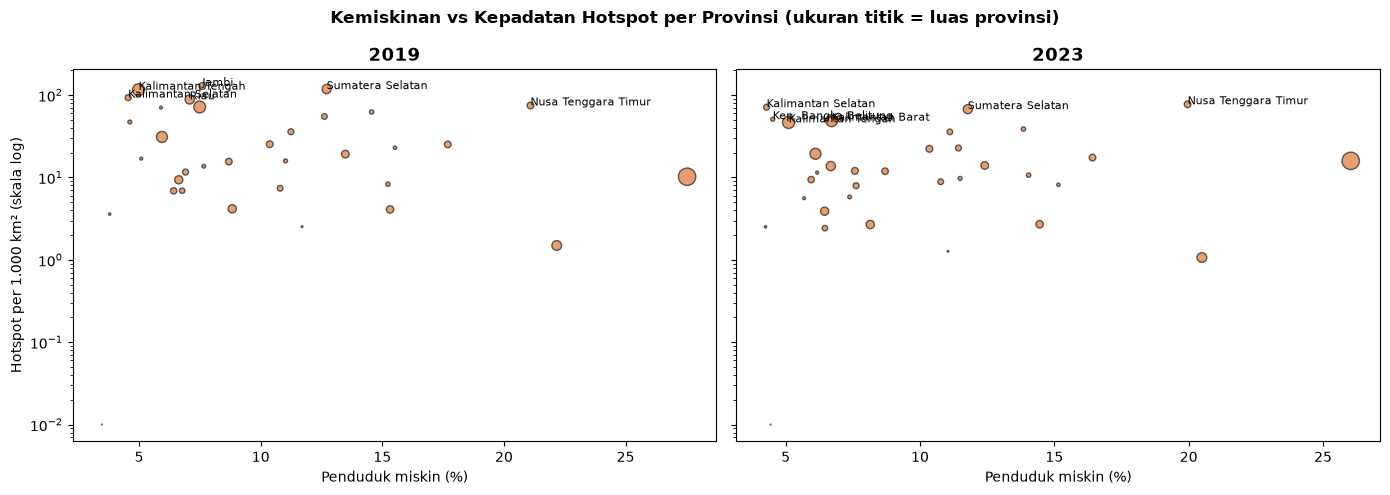

In [17]:
hasil = []
for th in TAHUN:
    for var in [f'miskin_pct_{th}', f'ipm_{th}', f'kepadatan_{th}' if th == 2023 else 'kepadatan_2019']:
        rho = gdf[f'dens_hotspot_{th}'].corr(gdf[var], method='spearman')
        hasil.append({'tahun': th, 'variabel': var, 'spearman_rho': round(rho, 3)})
display(pd.DataFrame(hasil))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, th in zip(axes, TAHUN):
    ax.scatter(gdf[f'miskin_pct_{th}'], gdf[f'dens_hotspot_{th}'] + 0.01, s=gdf.luas_km2 / 2000, alpha=0.6, color='#d95f0e', edgecolor='k')
    for _, r in gdf.nlargest(6, f'dens_hotspot_{th}').iterrows():
        ax.annotate(r.provinsi, (r[f'miskin_pct_{th}'], r[f'dens_hotspot_{th}'] + 0.01), fontsize=8)
    ax.set_yscale('log'); ax.set_xlabel('Penduduk miskin (%)'); ax.set_title(f'{th}')
axes[0].set_ylabel('Hotspot per 1.000 km² (skala log)')
fig.suptitle('Kemiskinan vs Kepadatan Hotspot per Provinsi (ukuran titik = luas provinsi)', fontweight='bold')
plt.tight_layout(); plt.show()

**Interpretasi uji pendukung:**
- Korelasi Spearman antara kepadatan hotspot dan **persentase kemiskinan mendekati nol** (ρ = −0,06 pada 2019 dan 0,09 pada 2023). Secara agregat provinsi, **tidak ada hubungan monoton** antara kemiskinan dan intensitas kebakaran, sehingga kesan visual dari peta overlay terkonfirmasi.
- Korelasi dengan **IPM** negatif lemah hingga sedang (ρ = −0,27 pada 2019 dan −0,40 pada 2023), dan dengan **kepadatan penduduk** negatif lemah (ρ ≈ −0,2). Kebakaran cenderung terjadi di provinsi yang **jarang penduduknya** dan memiliki **lahan vegetasi luas**, bukan di provinsi yang paling miskin.
- **Keterbatasan:** analisis ini dilakukan pada tingkat provinsi (n = 34). Hubungan di tingkat kabupaten atau desa bisa berbeda (*Modifiable Areal Unit Problem*), dan korelasi tidak menunjukkan sebab-akibat.

## 5. Teknik Visualisasi Lanjutan

Tiga teknik lanjutan diterapkan: **(a) Kernel Density Estimation**, **(b) Cartogram**, dan **(c) animasi spatio-temporal (GIF)**.

### 5.a Kernel Density Estimation (KDE) hotspot
KDE memperkirakan "permukaan kepadatan" kontinu dari sebaran titik, sehingga **hotspot** (wilayah konsentrasi kebakaran) terlihat jelas tanpa terganggu ribuan titik yang saling bertumpuk. Untuk efisiensi komputasi, KDE dihitung dari sampel acak 15.000 titik per tahun (atau semua titik jika lebih sedikit), dengan `random_state` tetap agar hasilnya reprodusibel.

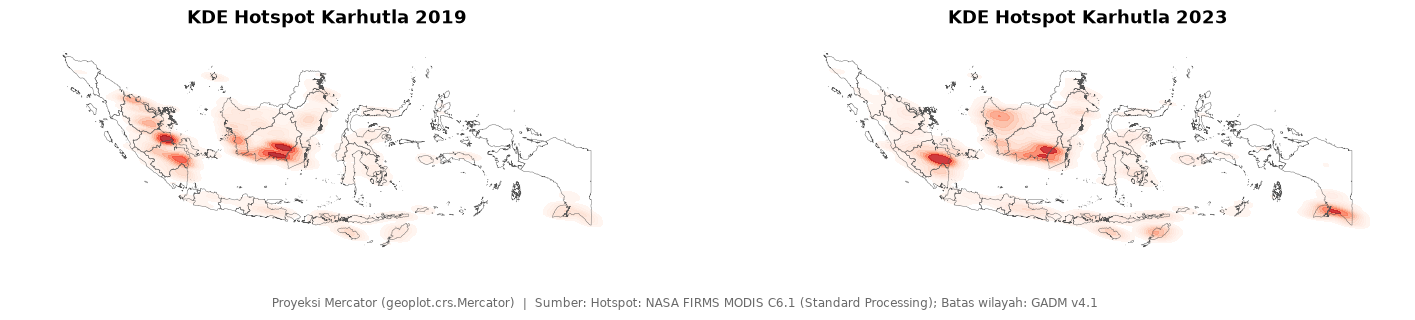

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), subplot_kw={'projection': PROJ})
for ax, th in zip(axes, TAHUN):
    p = pts[pts.tahun == th]
    p = p.sample(min(len(p), 15000), random_state=42)
    gplt.kdeplot(p, cmap='Reds', fill=True, thresh=0.05, levels=12, bw_adjust=0.35, alpha=0.85, ax=ax)
    gplt.polyplot(gplot, ax=ax, edgecolor='#555', linewidth=0.3, zorder=2)
    ax.set_title(f'KDE Hotspot Karhutla {th}')
keterangan(fig, f'{SRC_FIRMS}; {SRC_GEO}')
plt.savefig(f'{OUT_DIR}/07_kde_hotspot.png', bbox_inches='tight'); plt.show()

**Interpretasi KDE:**
- **2019** memperlihatkan **tiga puncak kepadatan utama** yang sangat kuat: (1) **pesisir timur Jambi**, (2) **Sumatera Selatan** bagian timur, dan (3) **Kalimantan Tengah bagian selatan**. Kepadatan sekunder terlihat di Riau, Kalimantan Barat, dan Kalimantan Selatan. Ketiga puncak utama berada di dataran rendah pesisir timur Sumatra dan selatan Kalimantan, yang dikenal sebagai kawasan gambut luas.
- **2023** masih menunjukkan puncak di **Sumatera Selatan** dan **Kalimantan Tengah–Selatan**, tetapi puncak Jambi **hampir hilang**. Muncul pula **hotspot baru yang jelas di Papua bagian selatan** (sekitar Merauke) serta kepadatan yang lebih menonjol di **NTT** dan **Kalimantan Barat**.
- KDE memperlihatkan pola yang sulit terlihat pada peta titik biasa: kebakaran tidak tersebar acak, melainkan **terkonsentrasi pada beberapa "kantong" berulang**. Sebagian kantong (Sumatera Selatan dan Kalimantan Tengah) muncul di kedua tahun, sehingga layak disebut **hotspot kronis**.

### 5.b Cartogram: luas provinsi diskalakan menurut jumlah hotspot
`gplt.cartogram` mengecilkan setiap polygon sesuai nilai variabel. Warna (hue) menunjukkan persentase penduduk miskin, sehingga cartogram ini mengkodekan dua dimensi sekaligus. Garis tipis abu-abu adalah batas asli provinsi sebagai pembanding.

Dua penyesuaian dilakukan agar cartogram **jujur dan sebanding antar tahun**:
1. **Skala ukuran bersama.** Secara default geoplot menskalakan ukuran relatif terhadap nilai maksimum *masing-masing* peta, sehingga provinsi teratas 2023 (7.163 hotspot) akan tampil sama besar dengan provinsi teratas 2019 (17.821 hotspot). Di sini dipakai `scale_func` dengan **satu acuan maksimum untuk kedua tahun**, sehingga hanya Kalimantan Tengah 2019 yang tampil 100%.
2. **Penyusutan luas sebanding jumlah hotspot.** Cartogram geoplot (*non-contiguous*) mengecilkan setiap provinsi relatif terhadap **luas aslinya sendiri**, pada sumbu x dan y sekaligus, sehingga luas berubah sebesar faktor². Karena itu faktor skala dibuat $\sqrt{\mathrm{hotspot}/\mathrm{maks}}$, sehingga **proporsi luas asli yang dipertahankan** sama dengan hotspot/maks. Contoh: provinsi dengan setengah hotspot maksimum tampil dengan 50% luas aslinya. Provinsi yang aslinya luas (mis. Papua) tetap terlihat besar walau proporsinya sama, jadi yang dibandingkan adalah **seberapa banyak polygon menyusut dari garis batas abu-abunya**.

3. **Diperkecil per pulau.** `gplt.cartogram` memperkecil setiap polygon ke arah titik tengah *bounding box*-nya. Jika provinsi kepulauan (mis. Maluku, NTT, Kalimantan Barat dengan Kepulauan Karimata) diperkecil sebagai satu kesatuan, pulau-pulaunya tertarik ke tengah dan warnanya keluar dari garis pantainya sendiri. Karena itu provinsi dipecah per pulau (`explode`), dan setiap pulau diperkecil di tempatnya dengan faktor skala provinsinya. Pulau mikro (< ±1 km²) dibuang khusus untuk peta ini, karena ring polygon sekecil itu rusak saat diperkecil.

Warna kelas terendah juga sengaja tidak dibuat putih, supaya provinsi dengan kemiskinan rendah tidak terlihat seperti polygon kosong.

Jumlah bagian (pulau) untuk cartogram: 1114 dari 34 provinsi


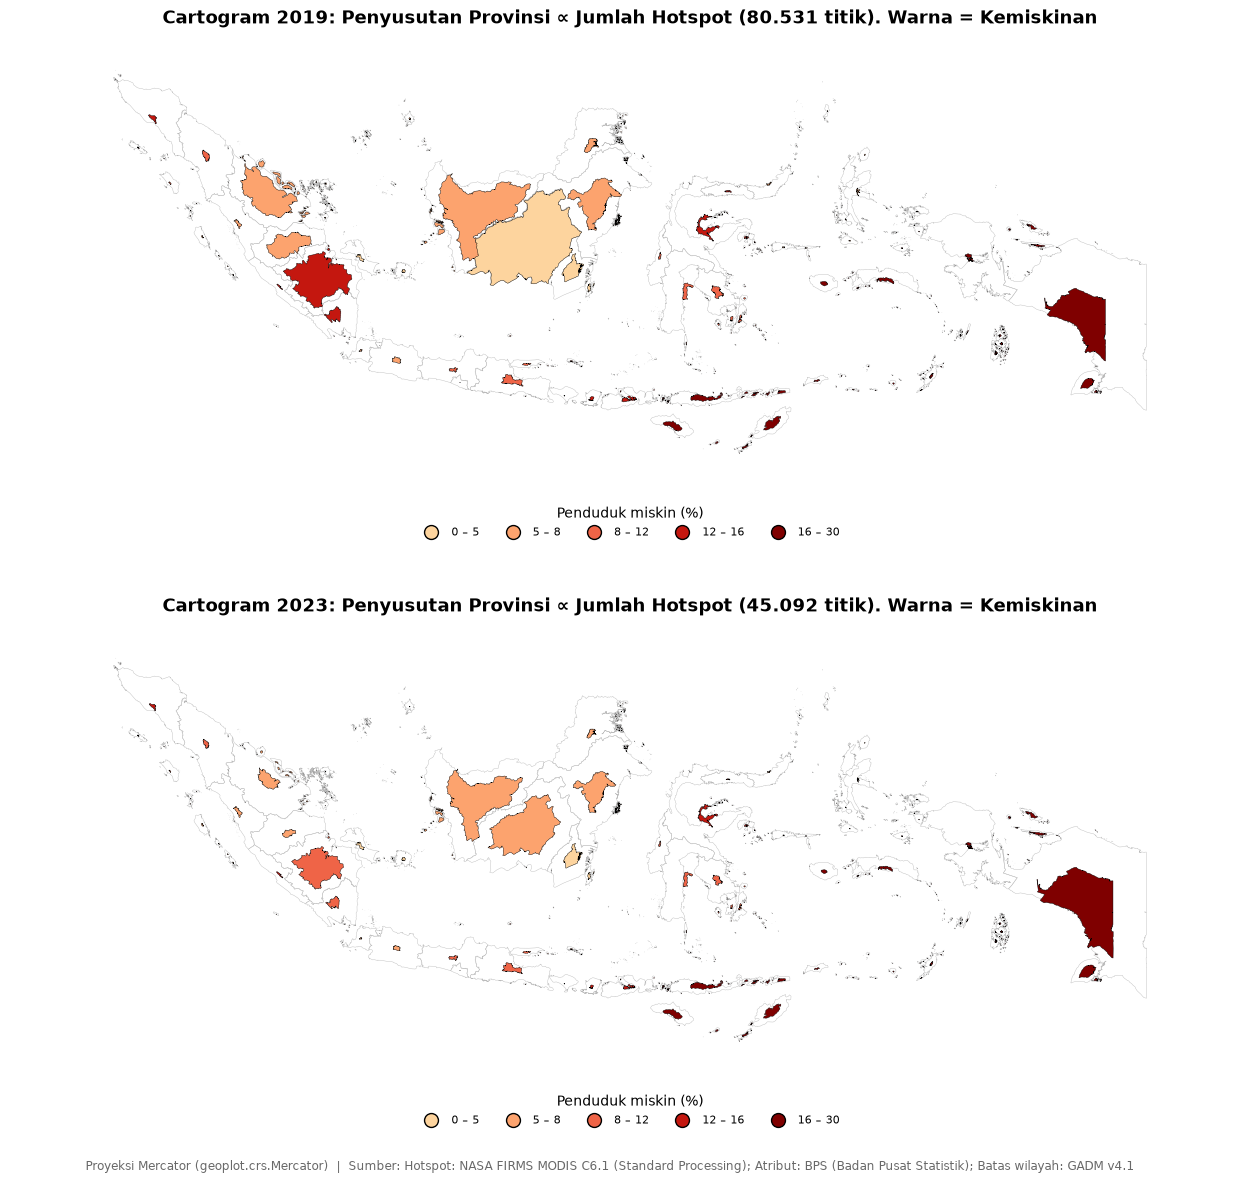

In [19]:
HOTSPOT_MAKS = max(gplot.hotspot_2019.max(), gplot.hotspot_2023.max())   # acuan bersama kedua tahun

def skala_bersama(dmin, dmax):
    """scale_func geoplot: abaikan min/maks per peta, pakai acuan bersama; akar kuadrat agar LUAS ∝ nilai."""
    return lambda v: max(np.sqrt(v / HOTSPOT_MAKS), 0.01)

# Pulau-pulau mikro (< ~1 km²) dibuang KHUSUS untuk cartogram: saat diperkecil, ring polygon sekecil ini
# menjadi rusak/terbalik sehingga cartopy mengisi "kebalikan" polygon ke seluruh peta.
def buang_pulau_mikro(geom, luas_min=1e-4):   # 1e-4 derajat² ≈ 1,2 km² di ekuator
    bagian = [p for p in getattr(geom, 'geoms', [geom]) if p.area >= luas_min]
    return MultiPolygon(bagian) if bagian else geom
gcarto = gplot.copy()
gcarto['geometry'] = gcarto.geometry.apply(buang_pulau_mikro)
# gplt.cartogram memperkecil polygon ke arah titik tengah bounding box-nya. Jika satu provinsi kepulauan
# diperkecil sebagai satu MultiPolygon, pulau-pulaunya akan "ditarik" ke tengah dan keluar dari garis
# pantainya sendiri. Karena itu provinsi dipecah per pulau (explode): tiap pulau mengecil di tempatnya
# dengan faktor skala provinsinya, sehingga warna tetap berada di dalam outline provinsi yang benar.
gcarto = gcarto.explode(index_parts=False).reset_index(drop=True)
print('Jumlah bagian (pulau) untuk cartogram:', len(gcarto), 'dari', gcarto.provinsi.nunique(), 'provinsi')

cmap_miskin = mcolors.ListedColormap(plt.get_cmap('OrRd')(np.linspace(0.25, 1, 5)))   # kelas terendah tidak putih

fig, axes = plt.subplots(2, 1, figsize=(16, 14), subplot_kw={'projection': PROJ})
for ax, th in zip(axes, TAHUN):
    gplt.cartogram(gcarto, scale=f'hotspot_{th}', scale_func=skala_bersama, hue=f'miskin_pct_{th}', cmap=cmap_miskin,
                   scheme=mc.UserDefined(gcarto[f'miskin_pct_{th}'], bins=[5, 8, 12, 16, 30]),
                   edgecolor='k', linewidth=0.3, ax=ax, legend=True, legend_var='hue', legend_labels=label_kelas([5, 8, 12, 16, 30], '{:.0f}'),
                   legend_kwargs={'loc': 'upper center', 'bbox_to_anchor': (0.5, -0.01), 'ncol': 5, 'frameon': False, 'title': 'Penduduk miskin (%)', 'fontsize': 8})
    gplt.polyplot(gplot, ax=ax, edgecolor='#bbb', linewidth=0.3, facecolor='none')
    ax.set_title(f'Cartogram {th}: Penyusutan Provinsi ∝ Jumlah Hotspot ({int(gplot[f"hotspot_{th}"].sum()):,} titik), Warna = Kemiskinan'.replace(',', '.'))
keterangan(fig, f'{SRC_FIRMS}; {SRC_BPS}; {SRC_GEO}', jarak=0.8)
plt.savefig(f'{OUT_DIR}/08_cartogram_hotspot.png', bbox_inches='tight'); plt.show()

**Interpretasi cartogram (skala bersama 2019 & 2023):**
- Pada **2019**, hanya **Kalimantan Tengah** yang tampil utuh (100% luas asli, 17.821 hotspot). **Kalimantan Barat** (±59% luas asli), **Sumatera Selatan** (±58%), **Riau** (±45%), dan **Jambi** (±35%) tetap besar. Sebagian besar provinsi lain menyusut hampir tak terlihat, termasuk seluruh Jawa, Bali, dan Sulawesi bagian utara. Ini menegaskan bahwa **beban kebakaran nasional ditanggung segelintir provinsi**.
- Warna polygon besar pada 2019 umumnya terang–sedang (kemiskinan 0–8%). Pengecualiannya adalah **Sumatera Selatan**, yang berwarna merah (12–16%).
- Karena skalanya sama, cartogram **2023 terlihat menyusut secara keseluruhan**, sesuai penurunan hotspot ±44%:
  - Kalimantan Tengah menyusut menjadi ±40% luas aslinya.
  - Riau dan Jambi hampir hilang (±7% dan ±3%).
  - Sumatera Selatan turun ke ±33% dan warnanya bergeser ke kelas 8–12% karena kemiskinannya turun.
- **Papua** (merah tua, kemiskinan > 16%) mempertahankan ±28% luas aslinya pada 2023, naik dari ±18% pada 2019. Karena luas asli Papua sangat besar, provinsi ini menjadi salah satu polygon paling mencolok di peta 2023. **NTT** (merah tua) juga tetap terlihat di kedua tahun. Cartogram 2023 memperlihatkan bahwa porsi beban kebakaran bergeser ke **provinsi miskin di timur Indonesia**, walaupun secara absolut kebakaran nasional menurun.

### 5.c Animasi spatio-temporal: hotspot bulanan 2019 vs 2023
Setiap frame menampilkan hotspot satu bulan untuk 2019 (kiri) dan 2023 (kanan) di atas peta dasar provinsi. Frame disimpan sebagai PNG lalu digabung menjadi GIF dengan **imageio**. Grafik garis di bawahnya merangkum jumlah hotspot per bulan.

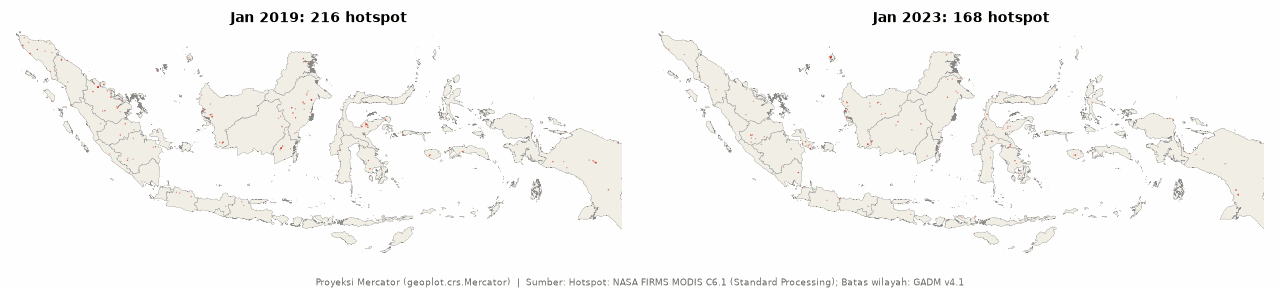

In [20]:
NAMA_BULAN = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
frames = []
for b in range(1, 13):
    fig, axes = plt.subplots(1, 2, figsize=(16, 3.6), subplot_kw={'projection': PROJ})
    fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.12, wspace=0.05)
    for ax, th in zip(axes, TAHUN):
        p = pts[(pts.tahun == th) & (pts.bulan == b)]
        gplt.polyplot(gplot, ax=ax, facecolor='#f2efe6', edgecolor='#888', linewidth=0.3)
        if len(p):
            gplt.pointplot(p, ax=ax, color='#d7301f', s=1.2, alpha=0.5, edgecolor='none', extent=gplot.total_bounds)
        ax.set_title(f'{NAMA_BULAN[b-1]} {th}: {len(p):,} hotspot'.replace(',', '.'))
    keterangan(fig, f'{SRC_FIRMS}; {SRC_GEO}')
    fn = f'{OUT_DIR}/frame_{b:02d}.png'
    fig.savefig(fn, dpi=80); plt.close(fig)
    frames.append(imageio.imread(fn))

GIF = f'{OUT_DIR}/09_animasi_hotspot_bulanan.gif'
imageio.mimsave(GIF, frames, duration=1.0, loop=0)
for b in range(1, 13):
    os.remove(f'{OUT_DIR}/frame_{b:02d}.png')
display(Image(filename=GIF))

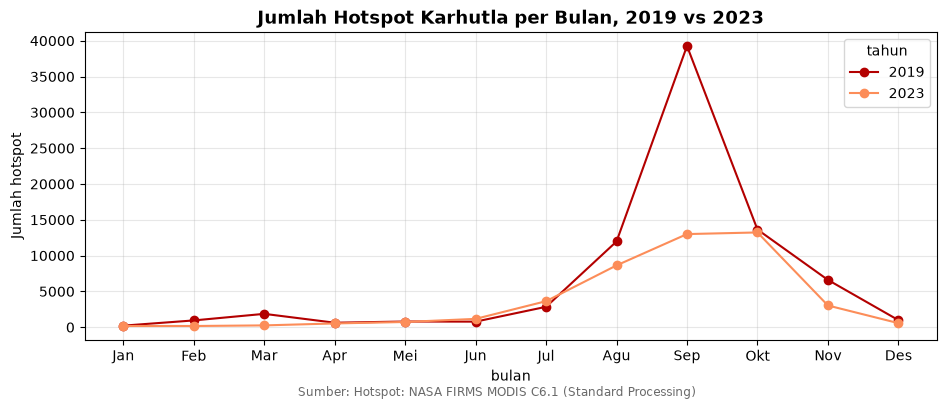

bulan,1,2,3,4,5,6,7,8,9,10,11,12
tahun,,,,,,,,,,,,
2019,216,946,1863,625,794,776,2848,11970,39265,13636,6603,989
2023,168,167,251,524,728,1163,3632,8629,13003,13230,3031,566


In [21]:
bulanan = pts.groupby(['bulan', 'tahun']).size().unstack('tahun').reindex(range(1, 13), fill_value=0)
ax = bulanan.plot(marker='o', figsize=(11, 4), color=['#b30000', '#fc8d59'])
ax.set_xticks(range(1, 13)); ax.set_xticklabels(NAMA_BULAN)
ax.set_ylabel('Jumlah hotspot'); ax.set_title('Jumlah Hotspot Karhutla per Bulan, 2019 vs 2023'); ax.grid(alpha=0.3)
plt.figtext(0.5, -0.03, f'Sumber: {SRC_FIRMS}', ha='center', fontsize=8.5, color='dimgray'); plt.show()
bulanan.T

**Interpretasi spatio-temporal:**
- Kedua tahun memiliki **pola musiman yang sama**: hotspot sangat sedikit pada Januari–Juni, meningkat tajam mulai Juli–Agustus, memuncak pada **September–Oktober**, lalu turun drastis pada November–Desember saat musim hujan datang. Pada 2019, **±81%** hotspot terjadi dalam tiga bulan (Agustus–Oktober), dan pada 2023 **±77%**.
- Bentuk puncaknya berbeda:
  - **2019** memiliki puncak yang **sangat tajam pada September** (39.265 hotspot, hampir 3 kali lipat bulan Oktober).
  - **2023** memiliki puncak yang **lebih landai dan bergeser lebih lambat**: September (13.003) dan Oktober (13.230) hampir sama. Jumlah hotspot Oktober 2023 bahkan hampir menyamai Oktober 2019 (13.636).
- Animasi juga memperlihatkan **pergerakan spasial** selama musim kebakaran:
  - **2019**: dimulai di Riau, NTT, dan Kalimantan Tengah (Juli). Kalimantan Barat memimpin pada Agustus. Kalimantan Tengah "meledak" pada September (12.706 hotspot dalam sebulan), diikuti Kalimantan Barat, Jambi, dan Sumatera Selatan. Pada Oktober–November, Sumatera Selatan memimpin, sementara Papua dan NTT mulai naik.
  - **2023**: Kalimantan Barat lebih dulu memuncak (Juli–Agustus). Kalimantan Tengah dan Sumatera Selatan memuncak pada September–Oktober, dan pada **November Papua menjadi provinsi dengan hotspot terbanyak**. Papua dan NTT menyumbang 46% hotspot bulan itu.
  - Pada kedua tahun, wilayah timur–selatan (Papua bagian selatan dan NTT) menjadi "ekor" musim kebakaran, karena musim kemaraunya berakhir lebih lambat.

## 6. Insight, Kesimpulan, dan Rekomendasi

### Insight kunci
1. **Kebakaran sangat terkonsentrasi.** Pada 2019, lima provinsi (Kalimantan Tengah, Kalimantan Barat, Sumatera Selatan, Riau, Jambi) menyumbang **±65%** dari seluruh hotspot nasional (52.863 dari 80.531). Cartogram dan peta Natural Breaks menunjukkan sebagian besar provinsi lain hampir tidak terdampak.
2. **Jumlah hotspot turun ±44% dari 2019 ke 2023, tetapi penurunannya tidak merata.** Riau (−84%) dan Jambi (−91%) turun drastis. Sebaliknya, **Papua naik +56%** (3.198 → 4.984) dan **NTT** sedikit naik (3.471 → 3.588), sehingga NTT menjadi provinsi dengan kepadatan hotspot tertinggi pada 2023.
3. **Sumatera Selatan dan Kalimantan Tengah adalah hotspot kronis.** Keduanya muncul sebagai puncak KDE pada 2019 maupun 2023, dan Sumatera Selatan konsisten berada di kelas kepadatan tinggi. Wilayah ini didominasi lahan gambut yang sulit dipadamkan.
4. **Kebakaran tidak berkorelasi dengan kemiskinan di tingkat provinsi** (Spearman ρ ≈ 0). Kebakaran lebih berkaitan dengan provinsi berpenduduk jarang dan bervegetasi luas (korelasi negatif dengan kepadatan penduduk dan IPM). Namun pada 2023 muncul kelompok **beban ganda**: **Papua dan NTT** yang termiskin di Indonesia kini juga mengalami peningkatan kebakaran.
5. **Musim kebakaran sangat terprediksi.** ±77–81% hotspot terjadi pada Agustus–Oktober. Pada 2023 puncaknya lebih landai dan berlanjut hingga Oktober, sehingga periode siaga perlu mencakup hingga akhir Oktober.
6. **Kesenjangan barat–timur pada kemiskinan dan IPM masih lebar.** Papua (kemiskinan 26,03%, IPM ±61) tertinggal jauh dari DKI Jakarta (4,44%, IPM 82,46). Penurunan kemiskinan terbesar 2019→2023 terjadi di Papua dan Papua Barat, sedangkan kemiskinan di Banten, DKI Jakarta, dan Jawa Barat justru naik.

### Kesimpulan
Visualisasi geospasial memperlihatkan bahwa karhutla di Indonesia adalah fenomena yang **terkonsentrasi secara spasial** (beberapa provinsi gambut di Sumatra dan Kalimantan) dan **terprediksi secara temporal** (Agustus–Oktober). Dari 2019 ke 2023 skala kebakaran nasional menurun, tetapi lokasinya **bergeser ke timur**, ke Papua bagian selatan dan NTT. Kedua provinsi ini adalah wilayah dengan kemiskinan tertinggi dan kapasitas penanganan yang lebih terbatas. Hubungan langsung antara kemiskinan dan kebakaran di tingkat provinsi tidak ditemukan, sehingga kebijakan penanggulangan karhutla dan pengentasan kemiskinan perlu dirancang dengan sasaran wilayah yang berbeda, kecuali di wilayah beban ganda.

### Rekomendasi
| Prioritas | Wilayah | Rekomendasi |
|---|---|---|
| **1. Hotspot kronis** | Sumatera Selatan, Kalimantan Tengah | Restorasi dan pembasahan kembali (*rewetting*) gambut, patroli terpadu, dan penempatan sumber daya pemadaman permanen sebelum Juli setiap tahun. |
| **2. Beban ganda (baru)** | Papua (bagian selatan), NTT | Pembangunan kapasitas Manggala Agni/BPBD setempat, sistem peringatan dini berbasis data FIRMS, dan program ekonomi alternatif agar pembukaan lahan tidak dilakukan dengan cara membakar. |
| **3. Pertahankan capaian** | Riau, Jambi | Evaluasi dan replikasi kebijakan yang berhasil menurunkan hotspot ±85–90% ke provinsi lain, serta tetap siaga karena kedua provinsi ini sangat rentan di tahun kering. |
| **4. Kalender siaga nasional** | Seluruh provinsi rawan | Status siaga karhutla dimulai Juli dan berlangsung hingga akhir Oktober, dengan puncak pengerahan sumber daya pada September–Oktober. |
| **5. Analisis lanjutan** | — | Mengulang analisis di tingkat kabupaten dan menambahkan data tutupan gambut serta curah hujan untuk menguji penyebab kebakaran secara lebih tepat. |

## 7. Daftar Pustaka / Referensi

**Sumber data**
1. GADM. (2022). *GADM database of Global Administrative Areas, version 4.1*: Indonesia level 1. https://gadm.org/download_country.html. File: https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_IDN_1.json.zip
2. Badan Pusat Statistik. *Persentase Penduduk Miskin (P0) Menurut Provinsi dan Daerah (Persen)*, 2019 & 2023. https://www.bps.go.id/id/statistics-table/2/MTkyIzI=/persentase-penduduk-miskin--p0--menurut-provinsi-dan-daerah--persen-.html
3. Badan Pusat Statistik. *[Metode Baru] Indeks Pembangunan Manusia (IPM) menurut Provinsi*, 2019 & 2023. https://www.bps.go.id/id/statistics-table/2/NDk0IzI=/indeks-pembangunan-manusia-menurut-provinsi.html
4. Badan Pusat Statistik. *Jumlah Penduduk, Laju Pertumbuhan Penduduk, Distribusi Persentase Penduduk, Kepadatan Penduduk, Rasio Jenis Kelamin Penduduk Menurut Provinsi*, 2019, 2023 & 2026. https://www.bps.go.id/id/statistics-table/3/V1ZSbFRUY3lTbFpEYTNsVWNGcDZjek53YkhsNFFUMDkjMyMwMDAw/jumlah-penduduk--laju-pertumbuhan-penduduk--distribusi-persentase-penduduk--kepadatan-penduduk--rasio-jenis-kelamin-penduduk-menurut-provinsi.html
5. NASA FIRMS. *MODIS Collection 6.1 Active Fire Detections (MODIS_SP)*, Area API. https://firms.modaps.eosdis.nasa.gov/api/area/

**Literatur & dokumentasi**

6. Giglio, L., Schroeder, W., & Justice, C. O. (2016). The collection 6 MODIS active fire detection algorithm and fire products. *Remote Sensing of Environment*, 178, 31–41.
7. Jenks, G. F. (1967). The data model concept in statistical mapping. *International Yearbook of Cartography*, 7, 186–190.
8. Dokumentasi GeoPandas: https://geopandas.org
9. Dokumentasi geoplot: https://residentmario.github.io/geoplot/
10. Dokumentasi mapclassify: https://pysal.org/mapclassify/
11. Dokumentasi Cartopy: https://scitools.org.uk/cartopy/
12. Materi Perkuliahan Visualisasi Data Minggu 10: Visualisasi Data Geospasial.